# Urdu OCR v2: CRNN + CTC trained on the merged dataset (~33k lines)

**What this notebook does**
- Trains a bigger CRNN (height 96, 8 conv layers, 3-layer BiLSTM) on the merged dataset (synthetic + real scans + news lines).
- Uses strong augmentation (rotation, shear, wave warp, blur, low resolution, JPEG, lighting, noise, extra margins) so it copes with scans and loosely cropped images.
- Normalizes polarity and contrast (light-on-dark text is flipped, tinted paper is stretched to white).
- The model reads one line at a time, so **inference auto-crops the margins and splits multi-line images into lines** (`ocr_lib.read_image`).
- Trains for as long as `TIME_BUDGET_HOURS` allows. It measures the speed of the first epoch and plans the epoch count and the learning-rate schedule from that.
- Splits the data per source (real scans split by page), so you get CER for each source separately.

**How to run:** attach the merged dataset (the folder with `images/`, `labels.txt`, `mapping.csv`), turn on a GPU, then **Save Version -> Save & Run All (Commit)**.
To check everything works first, set `SMOKE_TEST = True` in the next cell (a few minutes), then set it back to `False`.

**Honest limits:** the training data is *printed* Urdu. Handwriting, calligraphy and photos of whole pages with several columns are out of reach for this data.

In [1]:
import os, sys, glob, json, math, random, time, csv, re, traceback
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import torch, torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import cv2
cv2.setNumThreads(1)                                    # each data-loading worker uses 1 thread (no CPU oversubscription)

# ------------------------------ settings you may change ------------------------------
SMOKE_TEST = False          # True = tiny quick run to check that everything works before the long run
TIME_BUDGET_HOURS = 8.5     # training stops by itself after this long (Kaggle stops a run at 12 h)
MAX_EPOCHS = 150            # upper limit; the real number is planned from the measured epoch time
LR = 8e-4                   # peak learning rate
WEIGHT_DECAY = 1e-2
BATCH_PIX_W = 40 * 1024     # one batch holds at most (batch size x widest image) <= this many pixels of width
MAX_BATCH = 64
SEED = 42
MERGED_ROOT = None          # None = find it under /kaggle/input (folder with images/, labels.txt, mapping.csv)
# --------------------------------------------------------------------------------------
if SMOKE_TEST:
    TIME_BUDGET_HOURS, MAX_EPOCHS = 0.04, 3

OUT = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
use_amp = device.type == "cuda"                          # mixed precision: faster and lighter on the GPU
NUM_WORKERS = min(4, os.cpu_count() or 1)
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
print("device:", device, "| workers:", NUM_WORKERS, "| smoke test:", SMOKE_TEST)

device: cuda | workers: 4 | smoke test: False


## Shared library (written to `ocr_lib.py`)
Preprocessing, line splitting, the model and decoding live in one file, so training and the demo app use exactly the same code.

In [2]:
%%writefile ocr_lib.py
# ocr_lib.py - preprocessing, line splitting, model and decoding.
# Shared by the training notebook and the demo app, so training and inference can never drift apart.
import numpy as np
import torch, torch.nn as nn
from PIL import Image

IMG_H = 96            # every text line is resized to this height (must be a multiple of 32)
DOWN = 4              # the CNN shrinks the width by 4 -> one CTC time step per 4 pixels
TRAIN_MAX_W = 2048    # width cap while training
INFER_MAX_W = 4096    # width cap at inference (conv + LSTM accept longer lines than seen in training)


# ---------------------------------------------------------------- preprocessing
def normalize_gray(img):
    """PIL image -> uint8 gray array with DARK text on a LIGHT background and stretched contrast."""
    g = np.array(img.convert("L"), dtype=np.uint8)
    if g.size == 0:
        return g
    if g.mean() < 110:                              # light text on a dark background -> flip it
        g = 255 - g
    lo, hi = int(g.min()), int(np.percentile(g, 90))
    if hi - lo >= 30:                               # stretch contrast (yellowed paper, faded scans)
        g = np.clip((g.astype(np.float32) - lo) * (255.0 / (hi - lo)), 0, 255).astype(np.uint8)
    return g


def ink_mask(g):
    """True where a pixel looks like text (darker than the midpoint between ink and background)."""
    lo, hi = int(g.min()), int(np.percentile(g, 90))
    if hi - lo < 30:
        return np.zeros(g.shape, dtype=bool)
    return g < (lo + hi) / 2.0


def auto_crop(g, pad_frac=0.12):
    """Cut away empty margins around the text, keeping a small border (pad_frac of the text height)."""
    m = ink_mask(g)
    rp, cp = m.sum(1), m.sum(0)
    if rp.max() == 0:
        return g
    rows = np.flatnonzero(rp >= max(2, 0.03 * rp.max()))
    cols = np.flatnonzero(cp >= max(2, 0.03 * cp.max()))
    if len(rows) == 0 or len(cols) == 0:
        return g
    y0, y1, x0, x1 = rows[0], rows[-1] + 1, cols[0], cols[-1] + 1
    pad = int(round(pad_frac * (y1 - y0)))
    return g[max(0, y0 - pad):min(g.shape[0], y1 + pad), max(0, x0 - pad):min(g.shape[1], x1 + pad)]


def _runs(flags):
    runs, start = [], None
    for i, f in enumerate(flags):
        if f and start is None:
            start = i
        elif not f and start is not None:
            runs.append([start, i]); start = None
    if start is not None:
        runs.append([start, len(flags)])
    return runs


def _ref_height(runs):
    hs = np.array([e - s for s, e in runs], dtype=np.float32)
    return float(np.median(hs[hs >= 0.5 * hs.max()]))


def split_lines(g):
    """Split a page / multi-line image into single-line crops, top to bottom (horizontal projection profile)."""
    m = ink_mask(g)
    prof = m.sum(1).astype(np.float32)
    if prof.max() == 0:
        return [g]
    runs = _runs(prof >= max(2.0, 0.01 * prof.max()))
    if len(runs) <= 1:
        return [auto_crop(g)]
    ref = _ref_height(runs)
    merged = [runs[0]]
    for s, e in runs[1:]:                           # glue dots / diacritics that sit just above or below a line
        if s - merged[-1][1] < 0.3 * ref:
            merged[-1][1] = e
        else:
            merged.append([s, e])
    ref = _ref_height(merged)
    merged = [r for r in merged if r[1] - r[0] >= 0.3 * ref]   # drop specks
    if not merged:
        return [auto_crop(g)]
    lines = []
    for s, e in merged:
        p = int(0.15 * (e - s))
        lines.append(auto_crop(g[max(0, s - p):min(g.shape[0], e + p)]))
    return lines


def resize_line(g, max_w, width_factor=1.0):
    """Resize to height IMG_H keeping the aspect ratio (width is a multiple of DOWN)."""
    h, w = g.shape
    new_w = int(round(w * IMG_H / h * width_factor))
    new_w = max(DOWN * 4, min(max_w, new_w))
    new_w -= new_w % DOWN
    return np.array(Image.fromarray(g).resize((new_w, IMG_H), Image.BILINEAR))


def to_tensor(g):
    """uint8 (H, W) -> float tensor (1, H, W), white = 1. Mirrored because Urdu is written right to left."""
    g = np.ascontiguousarray(g[:, ::-1], dtype=np.uint8)
    return torch.from_numpy(g).float().div(255).unsqueeze(0)


# ---------------------------------------------------------------- model
def _cb(i, o):
    return [nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(inplace=True)]


class CRNN(nn.Module):
    def __init__(self, num_classes, img_h=IMG_H, rnn_hidden=256, rnn_layers=3, dropout=0.25):
        super().__init__()
        layers = (_cb(1, 64) + [nn.MaxPool2d((2, 2))] +
                  _cb(64, 128) + [nn.MaxPool2d((2, 2))] +
                  _cb(128, 256) + _cb(256, 256) + [nn.MaxPool2d((2, 1))] +
                  _cb(256, 512) + _cb(512, 512) + [nn.MaxPool2d((2, 1))] +
                  _cb(512, 512) + [nn.MaxPool2d((2, 1))])
        self.cnn = nn.Sequential(*layers)               # height /32, width /4
        feat = 512 * (img_h // 32)                      # 96 -> 3 rows x 512 channels = 1536 numbers per slice
        self.proj = nn.Sequential(nn.Linear(feat, 512), nn.ReLU(inplace=True), nn.Dropout(dropout))
        self.rnn = nn.LSTM(512, rnn_hidden, num_layers=rnn_layers, bidirectional=True,
                           batch_first=True, dropout=dropout)
        self.fc = nn.Linear(2 * rnn_hidden, num_classes)

    def forward(self, x):                               # x: (B, 1, H, W)
        x = self.cnn(x)                                 # (B, 512, H/32, W/4)
        b, c, h, w = x.shape
        x = x.reshape(b, c * h, w).permute(0, 2, 1)     # (B, slices, features)
        x = self.proj(x)
        x, _ = self.rnn(x)
        return self.fc(x)                               # (B, slices, num_classes)


# ---------------------------------------------------------------- decoding / prediction
def ids_to_text(ids, length, idx2char):
    """CTC greedy decode of one sequence: merge repeats, drop blanks (0). Only the first `length` slices are real."""
    text, prev = [], 0
    for k in ids[:length]:
        if k != prev and k != 0:
            text.append(idx2char[k])
        prev = k
    return "".join(text)


def decode_batch(out, lens, idx2char):
    best = out.argmax(2).cpu().tolist()
    return [ids_to_text(b, int(l), idx2char) for b, l in zip(best, lens)]


@torch.no_grad()
def predict_arrays(model, arrays, idx2char, device="cpu", max_w=INFER_MAX_W):
    model.eval()
    texts = []
    for g in arrays:
        x = to_tensor(resize_line(g, max_w)).unsqueeze(0).to(device)     # (1, 1, H, W)
        out = model(x)
        texts.append(decode_batch(out.float(), [x.shape[3] // DOWN], idx2char)[0])
    return texts


def read_image(img, model, idx2char, device="cpu", split=True):
    """PIL image (one line, an uncropped line, or a multi-line page) -> list of recognized lines."""
    g = normalize_gray(img)
    lines = split_lines(g) if split else [auto_crop(g)]
    lines = [l for l in lines if l.size and min(l.shape) >= 4]
    return predict_arrays(model, lines, idx2char, device)

Writing ocr_lib.py


In [3]:
sys.path.insert(0, os.getcwd())
import importlib, ocr_lib
importlib.reload(ocr_lib)
from ocr_lib import *
print("IMG_H", IMG_H, "| DOWN", DOWN, "| train max width", TRAIN_MAX_W)

IMG_H 96 | DOWN 4 | train max width 2048


## Load the merged dataset, build the vocabulary

In [4]:
def find_root():
    if MERGED_ROOT:
        return MERGED_ROOT
    for pat in ["/kaggle/input/*", "/kaggle/input/*/*", "/kaggle/input/*/*/*", "/kaggle/input/*/*/*/*"]:
        for d in sorted(glob.glob(pat)):
            if os.path.isfile(f"{d}/mapping.csv") and os.path.isfile(f"{d}/labels.txt") and os.path.isdir(f"{d}/images"):
                return d
    raise FileNotFoundError("Merged dataset not found. Attach it, or set MERGED_ROOT.")

ROOT = find_root()
print("dataset:", ROOT)

src_of, orig_of = {}, {}
with open(f"{ROOT}/mapping.csv", encoding="utf-8", newline="") as f:
    for r in csv.DictReader(f):
        src_of[r["new_name"]] = r["source"]
        orig_of[r["new_name"]] = r["original_name"]

names, texts = [], []
for line in open(f"{ROOT}/labels.txt", encoding="utf-8").read().splitlines():
    p = line.split(" ", 1)                               # "000123.png <text>"
    if len(p) == 2 and p[1].strip():
        names.append(p[0]); texts.append(p[1].strip())

if SMOKE_TEST:                                           # small random subset for the quick check
    keep = sorted(random.Random(0).sample(range(len(names)), min(len(names), 1500)))
    names, texts = [names[i] for i in keep], [texts[i] for i in keep]

paths = [f"{ROOT}/images/{n}" for n in names]

def get_size(p):                                         # read only the image header (fast)
    try:
        with Image.open(p) as im:
            return im.size
    except Exception:
        return None

t0 = time.time()
with ThreadPoolExecutor(16) as ex:
    sizes_all = list(ex.map(get_size, paths))
good = [i for i, s in enumerate(sizes_all) if s is not None and s[0] >= 4 and s[1] >= 4]
print(f"{len(paths)} labels, {len(paths) - len(good)} unreadable/tiny images dropped ({time.time() - t0:.0f}s)")
names = [names[i] for i in good]; texts = [texts[i] for i in good]
paths = [paths[i] for i in good]; sizes = [sizes_all[i] for i in good]
sources = [src_of.get(n, "unknown") for n in names]
N = len(names)

counts = Counter("".join(texts))
chars = sorted(counts)                                   # vocabulary from ALL labels (all sources)
char2idx = {c: i + 1 for i, c in enumerate(chars)}       # 0 is reserved for the CTC blank
idx2char = {i: c for c, i in char2idx.items()}
num_classes = len(chars) + 1
enc = [[char2idx[c] for c in t] for t in texts]
print("images:", N, "| characters:", len(chars), "| classes:", num_classes)
print("rare characters (<5 uses):", [c for c, k in counts.items() if k < 5][:40])
print("lines per source:", dict(Counter(sources)))

dataset: /kaggle/input/datasets/fifafootball/merged-dataset/merged
33171 labels, 0 unreadable/tiny images dropped (11s)
images: 33171 | characters: 163 | classes: 164
rare characters (<5 uses): ['؍', 'z', 'ې', 'b', 'N', 'v', 'Z', 'D', 'g', 'j', 'U', 'G', 'F', 'H', 'Y', 'ٖ', '٫', 'x', ',', 'B', 'J']
lines per source: {'synth': 20000, 'real_train1': 9065, 'real_train2': 2096, 'set3': 2010}


## Split per source (real scans by page) and plan the batches

In [5]:
def group_key(i):                                        # lines from the same page/block stay on the same side
    o = orig_of.get(names[i], names[i])
    m = re.match(r"^(\d+)_(\d+)_\d+\.", o)             # UTRSet-Real style: doc_page_line.jpg
    if m:
        return f"{sources[i]}:{m.group(1)}_{m.group(2)}"
    m = re.match(r"^(\d+)\.", o)                         # plain numbers: blocks of 50 consecutive lines
    if m:
        return f"{sources[i]}:blk{int(m.group(1)) // 50}"
    return f"{sources[i]}:{o}"

by_src = defaultdict(lambda: defaultdict(list))
for i in range(N):
    by_src[sources[i]][group_key(i)].append(i)

rng = random.Random(SEED)
train_ids, val_ids, test_ids = [], [], []
for s, groups in by_src.items():
    keys = sorted(groups); rng.shuffle(keys)
    nv = max(1, round(0.05 * len(keys))); nt = max(1, round(0.05 * len(keys)))
    for k in keys[:nv]:
        val_ids += groups[k]
    for k in keys[nv:nv + nt]:
        test_ids += groups[k]
    for k in keys[nv + nt:]:
        train_ids += groups[k]
print("split sizes  train/val/test:", len(train_ids), len(val_ids), len(test_ids))
for s in sorted(by_src):
    c = lambda ids: sum(sources[i] == s for i in ids)
    print(f"  {s:14s} train {c(train_ids):6d}  val {c(val_ids):5d}  test {c(test_ids):5d}")

def est_width(i, cap):                                   # width after resizing to IMG_H (used only to plan batches)
    w, h = sizes[i]
    return max(DOWN * 4, min(cap, int(round(w * IMG_H / h))))
w_train = [est_width(i, TRAIN_MAX_W) for i in range(N)]
w_eval = [est_width(i, INFER_MAX_W) for i in range(N)]

def feasible(i):                                         # CTC needs enough time steps for the label (+ repeated letters)
    reps = sum(a == b for a, b in zip(enc[i], enc[i][1:]))
    return (w_train[i] * 0.85) // DOWN >= len(enc[i]) + reps

train_ok = [i for i in train_ids if feasible(i)]
capped = sum(int(round(sizes[i][0] * IMG_H / sizes[i][1])) > TRAIN_MAX_W for i in train_ok)
print(f"train lines dropped (too many characters for their width): {len(train_ids) - len(train_ok)} | squashed by the width cap: {capped}")

def repeat_of(i):                                        # real scans are the target domain: show them twice per epoch
    return 2 if sources[i].startswith("real") else 1
train_list = [i for i in train_ok for _ in range(repeat_of(i))]
print("training samples per epoch:", len(train_list))

class BucketBatches:
    """Groups lines of similar width into the same batch (less padding, faster), within a pixel budget."""
    def __init__(self, ids, widths, shuffle):
        self.ids, self.widths, self.shuffle, self.batches = list(ids), widths, shuffle, []
        self.set_epoch(0)
    def set_epoch(self, epoch):
        rng = random.Random(SEED + epoch)
        ids = self.ids[:]
        if self.shuffle:
            rng.shuffle(ids)
        batches = []
        for c in range(0, len(ids), 2000):               # sort by width inside big random chunks
            cur, cur_max = [], 0
            for i in sorted(ids[c:c + 2000], key=lambda j: self.widths[j]):
                w = self.widths[i]
                if cur and (len(cur) + 1 > MAX_BATCH or (len(cur) + 1) * max(cur_max, w) > BATCH_PIX_W):
                    batches.append(cur); cur, cur_max = [], 0
                cur.append(i); cur_max = max(cur_max, w)
            if cur:
                batches.append(cur)
        if self.shuffle:
            rng.shuffle(batches)
        self.batches = batches
    def __iter__(self):
        return iter(self.batches)
    def __len__(self):
        return len(self.batches)

train_bs = BucketBatches(train_list, w_train, shuffle=True)
val_bs = BucketBatches(val_ids, w_eval, shuffle=False)
test_bs = BucketBatches(test_ids, w_eval, shuffle=False)
print("batches per epoch:", len(train_bs))

split sizes  train/val/test: 29913 1656 1602
  real_train1    train   8129  val   507  test   429
  real_train2    train   1974  val    49  test    73
  set3           train   1810  val   100  test   100
  synth          train  18000  val  1000  test  1000
train lines dropped (too many characters for their width): 114 | squashed by the width cap: 2153
training samples per epoch: 39899
batches per epoch: 960


## Augmentation, dataset and loaders

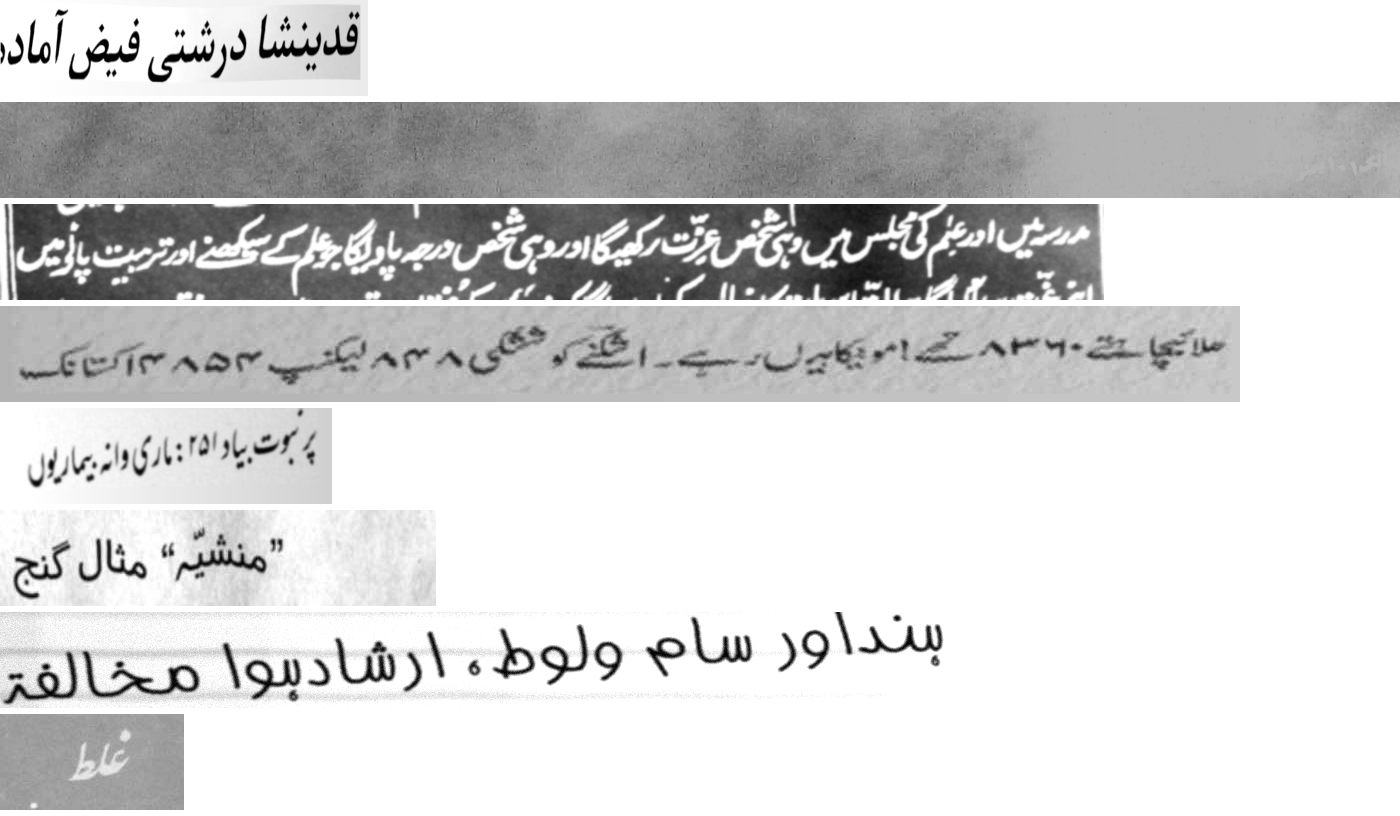

In [6]:
def aug_appearance(g):
    """Make a clean line look like a bad scan / photo. g: uint8 (IMG_H, W), dark text on light background."""
    h, w = g.shape
    if random.random() < 0.5:                                        # tiny rotation + shear
        lim = min(1.5, math.degrees(math.atan(0.15 * h / max(w / 2, 1))))
        M = cv2.getRotationMatrix2D((w / 2, h / 2), random.uniform(-lim, lim), 1.0)
        g = cv2.warpAffine(g, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
        sh = random.uniform(-0.2, 0.2)
        S = np.float32([[1, sh, -sh * h / 2], [0, 1, 0]])
        g = cv2.warpAffine(g, S, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    if random.random() < 0.3:                                        # wavy baseline (not perfectly straight)
        xs = np.arange(w, dtype=np.float32)
        shift = (random.uniform(0.5, 2.5) * np.sin(2 * np.pi * xs / random.uniform(80, 300) + random.uniform(0, 6.28))).astype(np.float32)
        map_x = np.tile(xs, (h, 1))
        map_y = np.arange(h, dtype=np.float32)[:, None] + shift[None, :]
        g = cv2.remap(g, map_x, map_y, cv2.INTER_LINEAR, borderMode=cv2.BORDER_REPLICATE)
    if random.random() < 0.3:                                        # thicker or thinner strokes
        k = np.ones((2, 2), np.uint8)
        g = cv2.erode(g, k) if random.random() < 0.5 else cv2.dilate(g, k)
    r = random.random()
    if r < 0.25:                                                     # blur
        g = cv2.GaussianBlur(g, (0, 0), random.uniform(0.4, 1.3))
    elif r < 0.35:                                                   # horizontal motion blur
        k = random.choice([3, 5, 7]); kern = np.zeros((k, k), np.float32); kern[k // 2, :] = 1.0 / k
        g = cv2.filter2D(g, -1, kern)
    if random.random() < 0.25:                                       # low resolution original
        f = random.uniform(0.35, 0.8)
        small = cv2.resize(g, (max(8, int(w * f)), max(8, int(h * f))), interpolation=cv2.INTER_AREA)
        g = cv2.resize(small, (w, h), interpolation=cv2.INTER_LINEAR)
    gf = g.astype(np.float32)
    if random.random() < 0.5:                                        # faded ink / different exposure
        gf = 128 + (gf - 128) * random.uniform(0.45, 1.0) + random.uniform(-25, 25)
        gf = 255 * (np.clip(gf, 0, 255) / 255.0) ** random.uniform(0.7, 1.6)
    if random.random() < 0.3:                                        # uneven lighting
        ramp = np.linspace(random.uniform(-0.2, 0.2), random.uniform(-0.2, 0.2), w, dtype=np.float32)[None, :]
        gf = gf * (1 + ramp)
    if random.random() < 0.35:                                       # sensor / scan noise
        gf = gf + np.random.normal(0, random.uniform(2, 14), gf.shape)
    g = np.clip(gf, 0, 255).astype(np.uint8)
    if random.random() < 0.3:                                        # JPEG artifacts
        ok, buf = cv2.imencode(".jpg", g, [cv2.IMWRITE_JPEG_QUALITY, random.randint(25, 85)])
        if ok:
            g = cv2.imdecode(buf, cv2.IMREAD_GRAYSCALE)
    return g

def load_gray(path, train):
    g = normalize_gray(Image.open(path))
    if not train:                                                    # evaluation = the same steps as real inference
        return resize_line(auto_crop(g, 0.1), INFER_MAX_W)
    if random.random() < 0.6:                                        # sometimes tight, sometimes the original margins
        g = auto_crop(g, random.uniform(0.03, 0.2))
    if random.random() < 0.25:                                       # loose crop: extra white margins like an uncropped photo
        h, w = g.shape
        fill = int(np.median(g))
        t, b = [int(random.uniform(0, 0.4) * h) for _ in range(2)]
        l, r = [int(random.uniform(0, 0.5) * h) for _ in range(2)]
        g = np.pad(g, ((t, b), (l, r)), constant_values=fill)
    g = resize_line(g, TRAIN_MAX_W, random.uniform(0.85, 1.15))      # also stretches/squeezes the width a bit
    return aug_appearance(g)

class LineDS(Dataset):
    def __init__(self, train):
        self.train = train
    def __len__(self):
        return N
    def __getitem__(self, i):                                        # i comes from BucketBatches
        for _ in range(4):
            try:
                return to_tensor(load_gray(paths[i], self.train)), torch.tensor(enc[i], dtype=torch.long), i
            except Exception:
                i = random.randrange(N)                              # never let one bad file kill a long run
        raise RuntimeError("too many unreadable images")

def collate(batch):
    xs, ys, ix = zip(*batch)
    wid = [x.shape[2] for x in xs]
    X = torch.ones(len(xs), 1, IMG_H, max(wid))                      # white canvas as wide as the widest line in THIS batch
    for k, x in enumerate(xs):
        X[k, :, :, :x.shape[2]] = x
    return X, torch.cat(ys), torch.tensor([len(y) for y in ys]), torch.tensor([w // DOWN for w in wid]), list(ix)

def make_loader(train, bs, persistent):
    kw = dict(batch_sampler=bs, collate_fn=collate, num_workers=NUM_WORKERS, pin_memory=use_amp)
    if NUM_WORKERS > 0:
        kw.update(persistent_workers=persistent, prefetch_factor=4)
    return DataLoader(LineDS(train), **kw)

train_loader = make_loader(True, train_bs, True)
val_loader = make_loader(False, val_bs, True)
test_loader = make_loader(False, test_bs, False)

# look at a few augmented training lines
try:
    rows = [load_gray(paths[i], True) for i in random.sample(train_list, 8)]
    W = min(1400, max(r.shape[1] for r in rows))
    canvas = np.full((len(rows) * (IMG_H + 6), W), 255, np.uint8)
    for k, r in enumerate(rows):
        canvas[k * (IMG_H + 6):k * (IMG_H + 6) + IMG_H, :min(W, r.shape[1])] = r[:, :W]
    Image.fromarray(canvas).save(f"{OUT}/aug_samples.png")
    display(Image.fromarray(canvas))
except Exception as e:
    print("preview skipped:", e)

## Metrics

In [7]:
try:
    from rapidfuzz.distance import Levenshtein as _Lev       # fast C implementation if available
    edit_distance = _Lev.distance
except Exception:
    def edit_distance(a, b):
        prev = list(range(len(b) + 1))
        for i, ca in enumerate(a, 1):
            row = [i]
            for j, cb in enumerate(b, 1):
                row.append(min(prev[j] + 1, row[j - 1] + 1, prev[j - 1] + (ca != cb)))
            prev = row
        return prev[-1]

@torch.no_grad()
def evaluate(model, loader):
    model.eval()
    stat, preds = defaultdict(lambda: [0, 0, 0, 0]), {}      # per source: edits, characters, lines, exact matches
    for x, tg, tl, il, ix in loader:
        with torch.autocast(device_type=device.type, enabled=use_amp):
            out = model(x.to(device, non_blocking=True))
        for i, p in zip(ix, decode_batch(out.float(), il, idx2char)):
            ref, s = texts[i], stat[sources[i]]
            s[0] += edit_distance(p, ref); s[1] += len(ref); s[2] += 1; s[3] += int(p == ref)
            preds[i] = p
    tot = [sum(v[k] for v in stat.values()) for k in range(4)]
    res = {"CER": tot[0] / max(tot[1], 1), "exact": tot[3] / max(tot[2], 1), "n": tot[2],
           "per_source": {s: {"CER": v[0] / max(v[1], 1), "exact": v[3] / max(v[2], 1), "n": v[2]} for s, v in stat.items()}}
    return res, preds

## Model and a quick self-test (fails early, before the long run, if something is wrong)

In [8]:
model = CRNN(num_classes).to(device)
print(f"parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.1f} M")

# 1) shapes + loss on random data
xb = torch.rand(2, 1, IMG_H, 256, device=device)
out = model(xb)
assert out.shape == (2, 256 // DOWN, num_classes), out.shape
l = nn.CTCLoss(blank=0, zero_infinity=True)(out.float().log_softmax(2).permute(1, 0, 2),
        torch.randint(1, num_classes, (10,)), torch.tensor([64, 64]), torch.tensor([5, 5]))
l.backward(); assert torch.isfinite(l)
model.zero_grad(set_to_none=True)

# 2) one real batch through the whole data pipeline
x, tg, tl, il, ix = next(iter(train_loader))
assert x.shape[2] == IMG_H and int(il.max()) <= x.shape[3] // DOWN and int(tl.sum()) == tg.numel()
print("one batch:", tuple(x.shape), "| longest label:", int(tl.max()), "| time steps:", int(il.max()))
print("self-test passed")

parameters: 12.5 M
one batch: (64, 1, 96, 348) | longest label: 49 | time steps: 87
self-test passed


## Training
The first epoch is also a speed test: the notebook then plans the number of epochs that fits in the time budget and decays the learning rate (cosine) over exactly that many epochs. The best model by validation CER is saved after every epoch.

In [9]:
ctc = nn.CTCLoss(blank=0, zero_infinity=True)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)
try:
    scaler = torch.amp.GradScaler(device.type, enabled=use_amp)
except Exception:                                        # older PyTorch
    scaler = torch.cuda.amp.GradScaler(enabled=use_amp)
BEST = f"{OUT}/crnn_best.pt"

def lr_at(ep_f, total):                                  # ep_f = epoch + fraction of the epoch done
    if ep_f < 1:
        return LR * (0.05 + 0.95 * ep_f)                 # warm-up during the first epoch
    if total is None:
        return LR
    p = min(1.0, (ep_f - 1) / max(total - 1, 1e-9))
    return LR * (0.02 + 0.98 * 0.5 * (1 + math.cos(math.pi * p)))

history, best, total = [], float("inf"), None
budget, t_start = TIME_BUDGET_HOURS * 3600, time.time()
try:
    ep = 0
    while True:
        train_bs.set_epoch(ep); nb = len(train_bs)
        model.train(); t0 = time.time(); run, cnt = 0.0, 0
        for bi, (x, tg, tl, il, ix) in enumerate(train_loader):
            for gp in opt.param_groups:
                gp["lr"] = lr_at(ep + bi / nb, total)
            with torch.autocast(device_type=device.type, enabled=use_amp):
                out = model(x.to(device, non_blocking=True))
            loss = ctc(out.float().log_softmax(2).permute(1, 0, 2), tg, il, tl)   # CTC in float32
            opt.zero_grad(set_to_none=True)
            if not torch.isfinite(loss):
                continue
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            nn.utils.clip_grad_norm_(model.parameters(), 5.0)
            scaler.step(opt); scaler.update()
            run += loss.item(); cnt += 1
            if bi % 200 == 0:
                print(f"  epoch {ep + 1} batch {bi}/{nb} loss {run / max(cnt, 1):.3f}", flush=True)
        res, _ = evaluate(model, val_loader)
        t_ep = time.time() - t0
        history.append({"epoch": ep + 1, "loss": run / max(cnt, 1), "val_CER": res["CER"], "val_exact": res["exact"], "lr": opt.param_groups[0]["lr"], "sec": t_ep})
        if res["CER"] < best:
            best = res["CER"]; torch.save(model.state_dict(), BEST)
        per = " ".join(f"{s}:{v['CER']:.3f}" for s, v in sorted(res["per_source"].items()))
        print(f"epoch {ep + 1:3d} | loss {history[-1]['loss']:.3f} | val CER {res['CER']:.4f} (best {best:.4f}) | exact {res['exact']:.3f} | {t_ep / 60:.1f} min | {per}", flush=True)
        if ep == 0:
            total = int(max(2, min(MAX_EPOCHS, 1 + 0.93 * (budget - (time.time() - t_start)) / t_ep)))
            print(f"==> epoch takes {t_ep / 60:.1f} min, so the plan is {total} epochs (~{total * t_ep / 3600:.1f} h)", flush=True)
        ep += 1
        if ep >= total:
            break
        if (time.time() - t_start) + 1.05 * t_ep > budget:
            print("time budget reached, stopping early"); break
except Exception:
    traceback.print_exc()
    print("!! training stopped by an error; continuing with the best checkpoint saved so far")

if os.path.exists(BEST):
    model.load_state_dict(torch.load(BEST, map_location=device))
print(f"finished: {len(history)} epochs in {(time.time() - t_start) / 3600:.2f} h | best val CER {best:.4f}")

  epoch 1 batch 0/960 loss 33.382
  epoch 1 batch 200/960 loss 7.111
  epoch 1 batch 400/960 loss 5.436
  epoch 1 batch 600/960 loss 4.827
  epoch 1 batch 800/960 loss 4.512
epoch   1 | loss 4.352 | val CER 1.0000 (best 1.0000) | exact 0.000 | 8.6 min | real_train1:1.000 real_train2:1.000 set3:1.000 synth:1.000
==> epoch takes 8.6 min, so the plan is 55 epochs (~7.9 h)
  epoch 2 batch 0/961 loss 3.542
  epoch 2 batch 200/961 loss 3.467
  epoch 2 batch 400/961 loss 3.398
  epoch 2 batch 600/961 loss 3.224
  epoch 2 batch 800/961 loss 3.006
epoch   2 | loss 2.831 | val CER 0.4103 (best 0.4103) | exact 0.005 | 8.8 min | real_train1:0.352 real_train2:0.351 set3:0.242 synth:0.481
  epoch 3 batch 0/961 loss 2.052
  epoch 3 batch 200/961 loss 1.597
  epoch 3 batch 400/961 loss 1.523
  epoch 3 batch 600/961 loss 1.447
  epoch 3 batch 800/961 loss 1.381
epoch   3 | loss 1.340 | val CER 0.2448 (best 0.2448) | exact 0.040 | 8.8 min | real_train1:0.183 real_train2:0.171 set3:0.067 synth:0.320
  ep

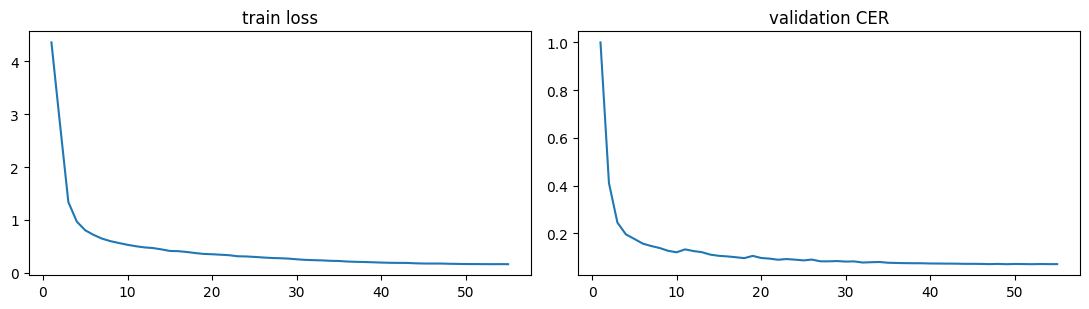

In [10]:
import matplotlib.pyplot as plt
if history:
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
    ax[0].plot([h["epoch"] for h in history], [h["loss"] for h in history]); ax[0].set_title("train loss")
    ax[1].plot([h["epoch"] for h in history], [h["val_CER"] for h in history]); ax[1].set_title("validation CER")
    plt.tight_layout(); plt.savefig(f"{OUT}/curves.png"); plt.show()

## Final test (lines the model never trained on), per source

In [11]:
res, pred = evaluate(model, test_loader)
print(f"TEST  CER {res['CER']:.4f} | exact match {res['exact']:.3f} | {res['n']} lines")
for s, v in sorted(res["per_source"].items()):
    print(f"  {s:14s} CER {v['CER']:.4f} | exact {v['exact']:.3f} | {v['n']} lines")
json.dump({"test": res, "history": history}, open(f"{OUT}/results.json", "w"), indent=1)

print()
shown = defaultdict(int)
for i in test_ids:                                       # a few examples per source
    if i in pred and shown[sources[i]] < 3:
        shown[sources[i]] += 1
        print(f"[{sources[i]}] TRUE: {texts[i]}\n{' ' * (len(sources[i]) + 2)} PRED: {pred[i]}\n")

TEST  CER 0.0719 | exact match 0.371 | 1602 lines
  real_train1    CER 0.0793 | exact 0.168 | 429 lines
  real_train2    CER 0.0663 | exact 0.123 | 73 lines
  set3           CER 0.0128 | exact 0.580 | 100 lines
  synth          CER 0.0760 | exact 0.455 | 1000 lines

[synth] TRUE: فقیر، حضاریۃ دیگر مثلاً اپنی ۳۴۱۔
        PRED: حقیر، حضاریۃ دیگر مثلاً اپنی ۳۴۱۔

[synth] TRUE: الزمان۔ نکلی
        PRED: الزمان۔ نکلی

[synth] TRUE: سمجھتے جائیگی کردیا؟ الموت سنپولیوں برساتا کاپرچہ فکرکریں۔ چہروں
        PRED: سمجھتے جائیگی کردیا؟ الموت سنپولیوں برساتا کاپرچہ فکرکریں۔ چہروں

[real_train1] TRUE: تقویظ
              PRED: تقویظ

[real_train1] TRUE: جناب نخامت نصاب ۔فضائل انتساب،خطیب غریب، ادیب، اریب، بلبل بوستان
              PRED: جناب نمامت نصاب۔ فضائل انتساب، خطیب غریب، ادیب ماریب ملیل بوستات

[real_train1] TRUE: معانی ۔ گلدستۂ بہار رستان نکتہ دانی مفسرآیات صمد مولنٰا السیّد محمد صاحب
              PRED: معانی۔ گلدستۂ بہارستان نکتہ دانی مفسر آبات رب صمد مولننا السیّد مققل حر ختلب

[real

## Uncropped inputs: stacked page and a degraded, loosely cropped line
These check the full inference pipeline (`read_image`: normalize -> split lines -> crop -> read) on inputs the model was *not* given as clean line crops.

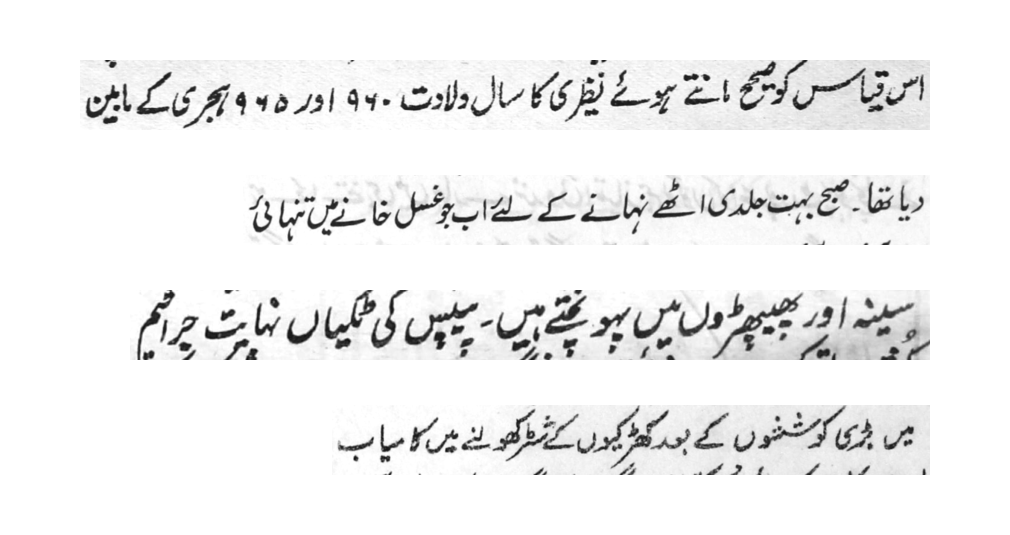

page: 4 real lines -> 4 lines found
  TRUE: اس قیاس کوصحیح مانتے ہوئے نظیری کاسال ولادت۰۶۹  اور ۵۶۹ ہجری کے مابین
  PRED: اس قیاس کو صیحح مانتے ہوئے نظیری کا سال ولادت ۹۹۰ اور ۹۹۵ ہجری کے مابین   (line CER 0.14)

  TRUE: دیاتھا۔ صبح بہت جلدی اٹھے نہانے کے لئے اب جو غسل خانے میں تنہائی
  PRED: دیاتھا۔ صبح بہت جلدی اٹھے نہانے کے لئے اب جو غسل خانے میں تنہائی   (line CER 0.00)

  TRUE: سینہ اور پھیپڑوں سے پہونچتے ہیں۔ پیپس کی ٹکیاں نہایت جراثیم
  PRED: ہسینہ اور پھیھڑوں میں پہونچتے ہیں۔ پیس کی ٹکیاں نہارت جرالم   (line CER 0.15)

  TRUE: میں بڑی کوششوں کے بعد کھڑکیوں کے شٹر کھولنے میں کامیاب
  PRED: میں بڑی کوششوں کے بعد کھڑکیوں کے شڑکھولنے میں کامیاب   (line CER 0.06)



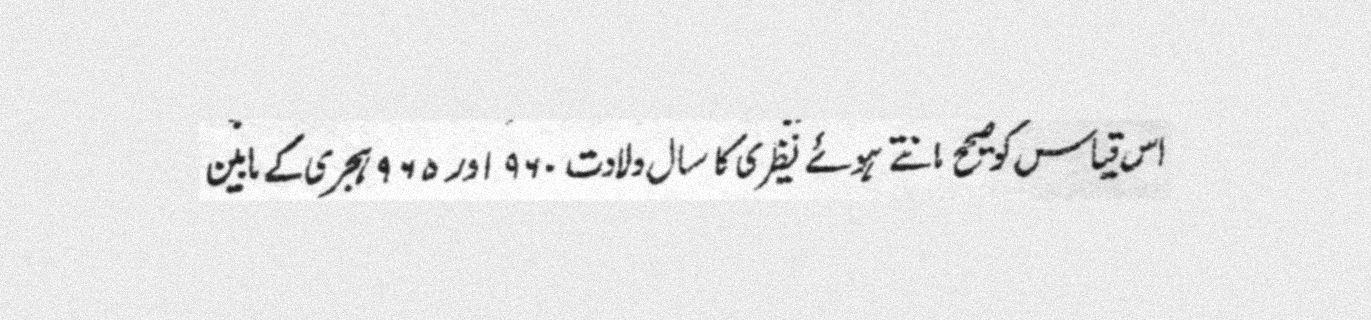

loose + noisy line  TRUE: اس قیاس کوصحیح مانتے ہوئے نظیری کاسال ولادت۰۶۹  اور ۵۶۹ ہجری کے مابین 
                    PRED: اس قیاس کو صیحح مانتے ہوئے نظیری کا سال ولادت ۹۹۰ اور ۹۹۵ ہجری کے مابین


In [12]:
def line_array(i, line_h=70):
    g = normalize_gray(Image.open(paths[i]))
    g = auto_crop(g, 0.1)
    return np.array(Image.fromarray(g).resize((max(8, int(g.shape[1] * line_h / g.shape[0])), line_h), Image.BILINEAR))

cand = [i for i in test_ids if sources[i].startswith("real") and 20 < len(texts[i]) < 70 and est_width(i, 99999) < 1800]
cand = cand or [i for i in test_ids if est_width(i, 99999) < 1800]
pick = random.Random(1).sample(cand, min(4, len(cand)))
arrs = [line_array(i) for i in pick]
W = max(a.shape[1] for a in arrs) + 160
page = np.full((60 * 2 + len(arrs) * 70 + (len(arrs) - 1) * 45, W), 255, np.uint8)
for k, a in enumerate(arrs):
    y = 60 + k * (70 + 45)
    page[y:y + 70, W - 80 - a.shape[1]:W - 80] = a        # right-aligned, like Urdu text
display(Image.fromarray(page))
got = read_image(Image.fromarray(page), model, idx2char, device)
print(f"page: {len(arrs)} real lines -> {len(got)} lines found")
for k, i in enumerate(pick):
    p = got[k] if k < len(got) else ""
    print(f"  TRUE: {texts[i]}\n  PRED: {p}   (line CER {edit_distance(p, texts[i]) / max(len(texts[i]), 1):.2f})\n")

# one line with big margins, noise and blur
a = line_array(pick[0], 80)
big = np.full((a.shape[0] * 4, a.shape[1] + 400), 235, np.uint8)
big[a.shape[0] * 3 // 2:a.shape[0] * 3 // 2 + a.shape[0], 200:200 + a.shape[1]] = a
big = cv2.GaussianBlur(big, (0, 0), 1.0).astype(np.float32) + np.random.normal(0, 8, big.shape)
big = Image.fromarray(np.clip(big, 0, 255).astype(np.uint8))
display(big)
p = " ".join(read_image(big, model, idx2char, device))
print("loose + noisy line  TRUE:", texts[pick[0]], "\n                    PRED:", p)

## Save everything you need for the demo

In [13]:
json.dump(chars, open(f"{OUT}/chars.json", "w", encoding="utf-8"), ensure_ascii=False)
json.dump({"IMG_H": IMG_H, "DOWN": DOWN, "num_classes": num_classes, "train_max_w": TRAIN_MAX_W, "infer_max_w": INFER_MAX_W},
          open(f"{OUT}/config.json", "w"), indent=1)
for f in sorted(os.listdir(OUT)):
    p = os.path.join(OUT, f)
    if os.path.isfile(p):
        print(f"{os.path.getsize(p) / 1e6:8.2f} MB  {f}")

    1.42 MB  __notebook__.ipynb
    0.25 MB  aug_samples.png
    0.00 MB  chars.json
    0.00 MB  config.json
   49.89 MB  crnn_best.pt
    0.02 MB  curves.png
    0.01 MB  ocr_lib.py
    0.01 MB  results.json


In [14]:
%%writefile app.py
import json
import streamlit as st
import torch
from PIL import Image
from ocr_lib import CRNN, read_image

@st.cache_resource                                   # load the model once, not on every click
def load():
    chars = json.load(open("chars.json", encoding="utf-8"))
    idx2char = {i + 1: c for i, c in enumerate(chars)}        # 0 = CTC blank
    model = CRNN(len(chars) + 1)
    model.load_state_dict(torch.load("crnn_best.pt", map_location="cpu"))
    model.eval()
    return model, idx2char

st.set_page_config(page_title="Urdu OCR")
st.title("Urdu OCR (CRNN + CTC)")
st.write("Upload an image of printed Urdu: a single line, a loosely cropped line or a few lines of text. "
         "Handwriting is not supported (the model was trained on printed text).")
file = st.file_uploader("Image", type=["png", "jpg", "jpeg"])
split = st.checkbox("Split into lines automatically", value=True)
if file is not None:
    img = Image.open(file)
    st.image(img, caption="Input")
    model, idx2char = load()
    lines = read_image(img, model, idx2char, "cpu", split=split)
    st.subheader("Recognized text")
    for t in lines:
        st.markdown(f'<div dir="rtl" style="font-size:30px">{t}</div>', unsafe_allow_html=True)

Writing app.py


## Using the results
Download these files from the notebook's **Output** tab: `crnn_best.pt`, `chars.json`, `ocr_lib.py`, `app.py` (Streamlit demo) and optionally `results.json`, `curves.png`.
Put them in one folder with this `requirements.txt` (for Streamlit Cloud):
```
--extra-index-url https://download.pytorch.org/whl/cpu
torch
streamlit
pillow
numpy
```
Locally: `pip install torch streamlit pillow numpy` and `streamlit run app.py`.